# 05 - CICIDS2017: Rigorous Multi-Seed Benchmark (3 ML Models + 1 DL Model)

## Academic & Reviewer Methodology Upgrades
This notebook implements publication-grade experimental standards to eliminate bias and leakage:

1. **Strict 3-Way Stratified Split (70% Train, 15% Validation, 15% Test)**:
   - **Zero Test Snooping**: The test partition is never seen during training, learning rate adjustment, or checkpoint selection.
   - The **Validation set** is used strictly for early stopping and the `ReduceLROnPlateau` scheduler.
2. **Class-Weighted CrossEntropyLoss for 1D-CNN**:
   - Level playing field with tree models (which use balanced weights).
   - Implements smoothed inverse-frequency weights (`sqrt(N / N_c)`) to prevent majority-class bias without gradient explosion.
3. **Stabilized Neural Convergence**:
   - 12 epochs with `AdamW(lr=0.002, weight_decay=1e-4)` and learning rate scheduling on validation Macro F1.
4. **Multi-Seed Statistical Significance (`Mean ± Std`)**:
   - Evaluates across **5 random seeds** (`[42, 123, 456, 789, 999]`).
   - Reports mean $\pm$ standard deviation for Accuracy, Weighted F1, and Macro F1 to prove statistical consistency.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
import xgboost as xgb
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

import warnings
warnings.filterwarnings('ignore')

# Compute device for Deep Learning
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Libraries imported successfully! Compute device: {device}")

Libraries imported successfully! Compute device: cpu


## 1. Load Clean Subset Dataset
Loads the fast-loading, pre-cleaned 169,686-row dataset (`CICIDS_clean_subset.parquet`).

In [2]:
t0 = time.time()
df = pd.read_parquet('../Datasets/CICIDS_clean_subset.parquet')
print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns in {time.time()-t0:.2f} seconds!")

X_all = df.drop(columns=['Label'])
y_all_raw = df['Label']

label_encoder = LabelEncoder()
y_all = label_encoder.fit_transform(y_all_raw)
classes = list(label_encoder.classes_)
num_classes = len(classes)

print(f"Target classes ({num_classes}): {classes}")
print("Target distribution in subset:")
print(df['Label'].value_counts())

Loaded 169,686 rows and 45 columns in 0.10 seconds!
Target classes (7): ['BENIGN', 'Bot', 'Brute Force', 'DDoS', 'DoS', 'PortScan', 'Web Attack']
Target distribution in subset:
Label
BENIGN         100000
DoS             30000
DDoS            25000
Brute Force      9150
Web Attack       2143
PortScan         1956
Bot              1437
Name: count, dtype: int64


## 2. Model Architecture Definitions

We define the 1D-CNN network and training loop helper with validation-based checkpointing.

In [3]:
class Fast1DCNN(nn.Module):
    def __init__(self, in_features=44, num_classes=7):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, num_classes)
        )
        
    def forward(self, x):
        return self.net(x.unsqueeze(1))

def train_cnn_with_val(model, train_loader, val_loader, criterion, epochs=12, lr=0.002):
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)
    
    best_val_macro_f1 = -1.0
    best_weights = None
    start_time = time.time()
    
    for epoch in range(1, epochs + 1):
        model.train()
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            logits = model(bx)
            loss = criterion(logits, by)
            loss.backward()
            optimizer.step()
            
        # Validation (used ONLY for scheduling & checkpointing)
        model.eval()
        val_preds, val_targets = [], []
        with torch.no_grad():
            for bx, by in val_loader:
                bx = bx.to(device)
                preds = torch.argmax(model(bx), dim=1).cpu().numpy()
                val_preds.extend(preds)
                val_targets.extend(by.numpy())
                
        val_acc = accuracy_score(val_targets, val_preds)
        val_mf1 = f1_score(val_targets, val_preds, average="macro", zero_division=0)
        scheduler.step(val_mf1)
        
        if val_mf1 > best_val_macro_f1:
            best_val_macro_f1 = val_mf1
            best_weights = model.state_dict().copy()
            
    train_time = time.time() - start_time
    model.load_state_dict(best_weights)
    return model, train_time

def predict_dl(model, loader):
    model.eval()
    all_preds = []
    with torch.no_grad():
        for bx, _ in loader:
            bx = bx.to(device)
            preds = torch.argmax(model(bx), dim=1).cpu().numpy()
            all_preds.extend(preds)
    return np.array(all_preds)

print("Architecture and validation training pipeline defined.")

Architecture and validation training pipeline defined.


## 3. Multi-Seed Rigorous Evaluation Loop

We run across **5 distinct random seeds** (`[42, 123, 456, 789, 999]`).
In each run:
- Data is partitioned into **70% Train, 15% Validation, 15% Test** using stratified sampling.
- Scaler is fit strictly on Train and transforms Val and Test.
- 1D-CNN uses smoothed class-weighted loss and stops on Validation.
- All 4 models are evaluated strictly on the untouched **15% Test set**.

In [4]:
SEEDS = [42, 123, 456, 789, 999]
raw_results = []
saved_models_best_seed = {}
saved_test_data = {}

print(f"Beginning 5-Seed Benchmark across {len(SEEDS)} seeds: {SEEDS}...")
start_benchmark = time.time()

for seed_idx, seed in enumerate(SEEDS):
    print(f"\n=================== RUNNING SEED {seed} ({seed_idx + 1}/{len(SEEDS)}) ===================")
    np.random.seed(seed)
    torch.manual_seed(seed)
    
    # 1. Strict 70% Train / 15% Validation / 15% Test Stratified Split
    X_train, X_temp, y_train, y_temp = train_test_split(
        X_all, y_all, test_size=0.30, stratify=y_all, random_state=seed
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=seed
    )
    
    # 2. Scaling (Fit ONLY on Train)
    scaler = StandardScaler()
    X_train_s = np.clip(scaler.fit_transform(X_train), -10, 10)
    X_val_s = np.clip(scaler.transform(X_val), -10, 10)
    X_test_s = np.clip(scaler.transform(X_test), -10, 10)
    
    # 3. Balanced Sample Weights for XGBoost & Class Weights for CNN
    sample_weights_train = compute_sample_weight('balanced', y_train)
    
    class_counts = np.bincount(y_train)
    raw_weights = np.sqrt(len(y_train) / class_counts)
    smoothed_weights = raw_weights / np.mean(raw_weights)
    weights_tensor = torch.tensor(smoothed_weights, dtype=torch.float32).to(device)
    cnn_criterion = nn.CrossEntropyLoss(weight=weights_tensor)
    
    # 4. Initialize Models for current seed
    models_to_run = {
        "Random Forest (Balanced)": RandomForestClassifier(
            n_estimators=100, max_depth=16, min_samples_leaf=10,
            class_weight='balanced_subsample', random_state=seed, n_jobs=-1
        ),
        "LightGBM (Balanced)": LGBMClassifier(
            n_estimators=150, max_depth=8, learning_rate=0.05,
            is_unbalance=True, random_state=seed, n_jobs=-1, verbose=-1
        ),
        "XGBoost (Balanced)": xgb.XGBClassifier(
            n_estimators=150, max_depth=6, learning_rate=0.08,
            tree_method='hist', random_state=seed, n_jobs=-1, eval_metric='mlogloss'
        )
    }
    
    # Train & Evaluate ML Models
    for name, model in models_to_run.items():
        t_start = time.time()
        if name == "XGBoost (Balanced)":
            model.fit(X_train_s, y_train, sample_weight=sample_weights_train)
        else:
            model.fit(X_train_s, y_train)
        train_time = time.time() - t_start
        
        preds = model.predict(X_test_s)
        acc = accuracy_score(y_test, preds)
        wf1 = f1_score(y_test, preds, average='weighted', zero_division=0)
        mf1 = f1_score(y_test, preds, average='macro', zero_division=0)
        
        raw_results.append({
            "Seed": seed,
            "Model": name,
            "Type": "Machine Learning",
            "Accuracy": acc,
            "Weighted F1": wf1,
            "Macro F1": mf1,
            "Train Time (s)": train_time
        })
        print(f"  {name:25s} | Acc: {acc:.4f} | Macro F1: {mf1:.4f} | Time: {train_time:.1f}s")
        
        if seed == SEEDS[0]:
            saved_models_best_seed[name] = model
            
    # Train & Evaluate 1D-CNN
    train_loader = DataLoader(TensorDataset(torch.tensor(X_train_s, dtype=torch.float32), torch.tensor(y_train, dtype=torch.long)), batch_size=512, shuffle=True)
    val_loader = DataLoader(TensorDataset(torch.tensor(X_val_s, dtype=torch.float32), torch.tensor(y_val, dtype=torch.long)), batch_size=1024, shuffle=False)
    test_loader = DataLoader(TensorDataset(torch.tensor(X_test_s, dtype=torch.float32), torch.tensor(y_test, dtype=torch.long)), batch_size=1024, shuffle=False)
    
    cnn_model = Fast1DCNN(in_features=44, num_classes=num_classes).to(device)
    cnn_model, cnn_train_time = train_cnn_with_val(cnn_model, train_loader, val_loader, cnn_criterion, epochs=12, lr=0.002)
    
    cnn_preds = predict_dl(cnn_model, test_loader)
    cnn_acc = accuracy_score(y_test, cnn_preds)
    cnn_wf1 = f1_score(y_test, cnn_preds, average='weighted', zero_division=0)
    cnn_mf1 = f1_score(y_test, cnn_preds, average='macro', zero_division=0)
    
    raw_results.append({
        "Seed": seed,
        "Model": "1D-CNN (PyTorch)",
        "Type": "Deep Learning",
        "Accuracy": cnn_acc,
        "Weighted F1": cnn_wf1,
        "Macro F1": cnn_mf1,
        "Train Time (s)": cnn_train_time
    })
    print(f"  {'1D-CNN (PyTorch)':25s} | Acc: {cnn_acc:.4f} | Macro F1: {cnn_mf1:.4f} | Time: {cnn_train_time:.1f}s")
    
    if seed == SEEDS[0]:
        saved_models_best_seed["1D-CNN (PyTorch)"] = cnn_model
        saved_test_data["X_test_s"] = X_test_s
        saved_test_data["y_test"] = y_test
        saved_test_data["test_loader"] = test_loader
        saved_test_data["scaler"] = scaler

print(f"\nAll 5 seeds completed in {time.time()-start_benchmark:.1f} seconds!")

Beginning 5-Seed Benchmark across 5 seeds: [42, 123, 456, 789, 999]...

=================== RUNNING SEED 42 (1/5) ===================
  Random Forest (Balanced)  | Acc: 0.9923 | Macro F1: 0.9606 | Time: 4.4s
  LightGBM (Balanced)       | Acc: 0.9987 | Macro F1: 0.9925 | Time: 5.6s
  XGBoost (Balanced)        | Acc: 0.9975 | Macro F1: 0.9865 | Time: 8.5s
  1D-CNN (PyTorch)          | Acc: 0.9511 | Macro F1: 0.8743 | Time: 67.4s

=================== RUNNING SEED 123 (2/5) ===================
  Random Forest (Balanced)  | Acc: 0.9917 | Macro F1: 0.9579 | Time: 3.8s
  LightGBM (Balanced)       | Acc: 0.9984 | Macro F1: 0.9916 | Time: 5.5s
  XGBoost (Balanced)        | Acc: 0.9975 | Macro F1: 0.9871 | Time: 6.0s
  1D-CNN (PyTorch)          | Acc: 0.9637 | Macro F1: 0.8880 | Time: 65.5s

=================== RUNNING SEED 456 (3/5) ===================
  Random Forest (Balanced)  | Acc: 0.9916 | Macro F1: 0.9553 | Time: 3.8s
  LightGBM (Balanced)       | Acc: 0.9984 | Macro F1: 0.9914 | Time: 5

## 4. Multi-Seed Statistical Summary Table (`Mean ± Std`)

Computes the statistical mean and sample standard deviation across all 5 independent runs.

In [5]:
raw_df = pd.DataFrame(raw_results)

# Aggregate across seeds
agg_df = raw_df.groupby(['Model', 'Type']).agg({
    'Accuracy': ['mean', 'std'],
    'Weighted F1': ['mean', 'std'],
    'Macro F1': ['mean', 'std'],
    'Train Time (s)': ['mean', 'std']
}).reset_index()

# Format as publication-ready string (Mean ± Std)
summary_rows = []
for _, row in agg_df.iterrows():
    model_name = row[('Model', '')]
    model_type = row[('Type', '')]
    acc_str = f"{row[('Accuracy', 'mean')]:.4f} ± {row[('Accuracy', 'std')]:.4f}"
    wf1_str = f"{row[('Weighted F1', 'mean')]:.4f} ± {row[('Weighted F1', 'std')]:.4f}"
    mf1_str = f"{row[('Macro F1', 'mean')]:.4f} ± {row[('Macro F1', 'std')]:.4f}"
    time_str = f"{row[('Train Time (s)', 'mean')]:.2f} ± {row[('Train Time (s)', 'std')]:.2f}s"
    
    summary_rows.append({
        "Model": model_name,
        "Type": model_type,
        "Accuracy (Mean ± Std)": acc_str,
        "Weighted F1 (Mean ± Std)": wf1_str,
        "Macro F1 (Mean ± Std)": mf1_str,
        "Train Time (s)": time_str,
        "Raw_Acc_Mean": row[('Accuracy', 'mean')],
        "Raw_Acc_Std": row[('Accuracy', 'std')],
        "Raw_MF1_Mean": row[('Macro F1', 'mean')],
        "Raw_MF1_Std": row[('Macro F1', 'std')],
        "Raw_WF1_Mean": row[('Weighted F1', 'mean')],
        "Raw_WF1_Std": row[('Weighted F1', 'std')]
    })

final_summary_df = pd.DataFrame(summary_rows).sort_values(by="Raw_MF1_Mean", ascending=False).reset_index(drop=True)

# Display clean table
display_cols = ["Model", "Type", "Accuracy (Mean ± Std)", "Weighted F1 (Mean ± Std)", "Macro F1 (Mean ± Std)", "Train Time (s)"]
display(final_summary_df[display_cols].style.set_properties(**{'text-align': 'center'}))

,Model,Type,Accuracy (Mean ± Std),Weighted F1 (Mean ± Std),Macro F1 (Mean ± Std),Train Time (s)
0,LightGBM (Balanced),Machine Learning,0.9985 ± 0.0001,0.9985 ± 0.0001,0.9917 ± 0.0004,5.54 ± 0.07s
1,XGBoost (Balanced),Machine Learning,0.9975 ± 0.0001,0.9976 ± 0.0001,0.9869 ± 0.0004,6.56 ± 1.11s
2,Random Forest (Balanced),Machine Learning,0.9919 ± 0.0003,0.9924 ± 0.0002,0.9586 ± 0.0021,3.86 ± 0.31s
3,1D-CNN (PyTorch),Deep Learning,0.9548 ± 0.0104,0.9562 ± 0.0098,0.8866 ± 0.0198,65.77 ± 1.11s


## 5. Visual Comparison with Statistical Error Bars

Bar charts displaying the empirical mean score with error bars representing $\pm 1$ standard deviation across the 5 independent seeds.

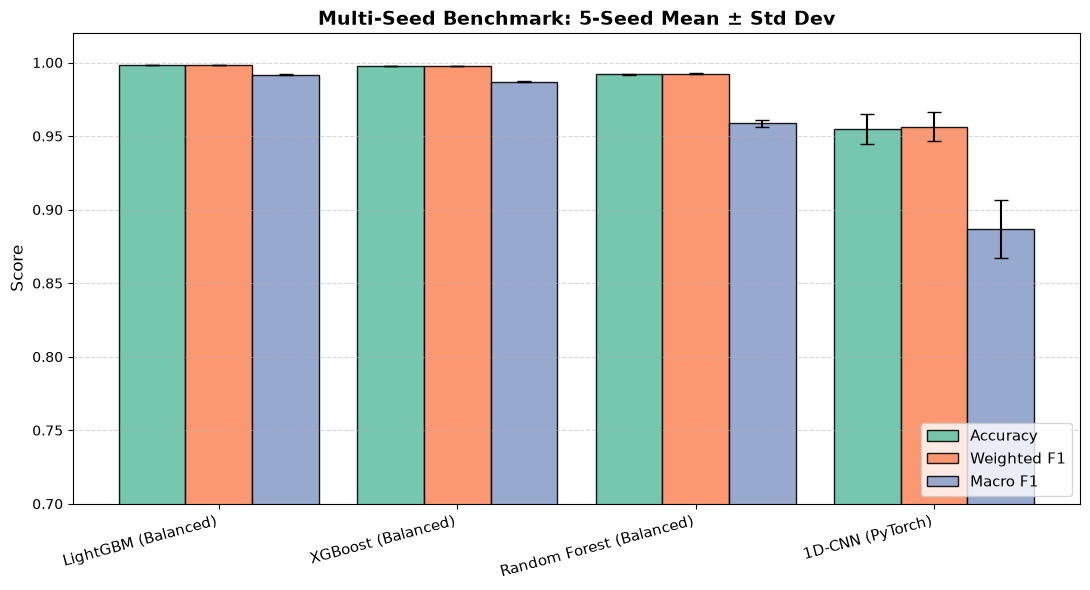

In [6]:
plt.figure(figsize=(11, 6))

# Plot Macro F1 and Accuracy with standard deviation error bars
x = np.arange(len(final_summary_df))
width = 0.28

plt.bar(x - width, final_summary_df["Raw_Acc_Mean"], width, yerr=final_summary_df["Raw_Acc_Std"],
        capsize=5, label="Accuracy", color="#66c2a5", edgecolor="black", alpha=0.9)
plt.bar(x, final_summary_df["Raw_WF1_Mean"], width, yerr=final_summary_df["Raw_WF1_Std"],
        capsize=5, label="Weighted F1", color="#fc8d62", edgecolor="black", alpha=0.9)
plt.bar(x + width, final_summary_df["Raw_MF1_Mean"], width, yerr=final_summary_df["Raw_MF1_Std"],
        capsize=5, label="Macro F1", color="#8da0cb", edgecolor="black", alpha=0.9)

plt.title("Multi-Seed Benchmark: 5-Seed Mean ± Std Dev", fontsize=14, fontweight="bold")
plt.xticks(x, final_summary_df["Model"], fontsize=11, rotation=15, ha="right")
plt.ylabel("Score", fontsize=12)
plt.ylim(0.70, 1.02)
plt.legend(loc="lower right", frameon=True, fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 6. Detailed Classification Report & Confusion Matrix (Best Model on Held-out Test Set)

=== Top Performing Model Across 5 Seeds: LightGBM (Balanced) ===

Detailed Per-Class Performance on Unseen Test Partition:
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     15000
         Bot       0.97      0.99      0.98       216
 Brute Force       1.00      1.00      1.00      1372
        DDoS       1.00      1.00      1.00      3750
         DoS       1.00      1.00      1.00      4500
    PortScan       0.98      0.98      0.98       294
  Web Attack       0.99      0.98      0.99       321

    accuracy                           1.00     25453
   macro avg       0.99      0.99      0.99     25453
weighted avg       1.00      1.00      1.00     25453



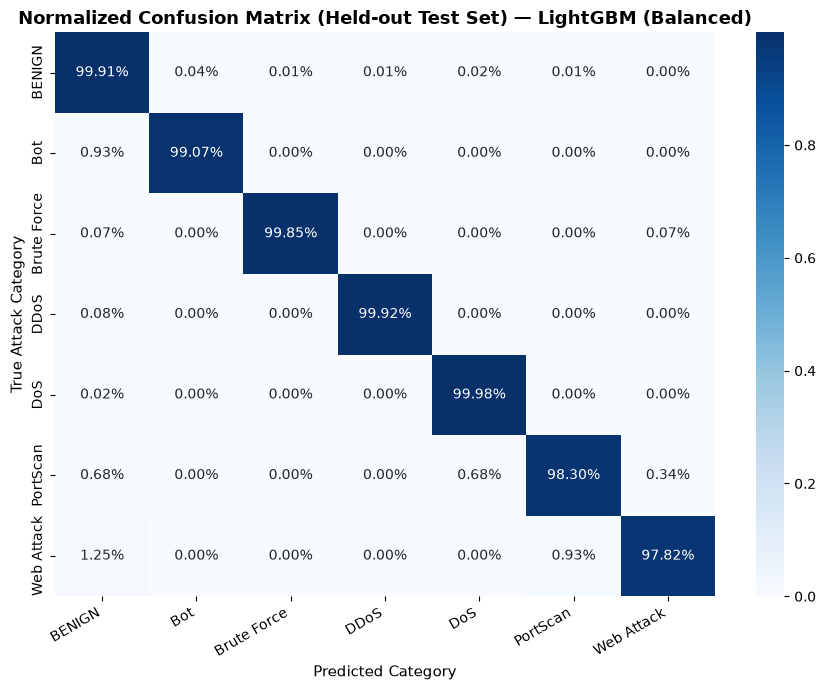

In [7]:
best_model_name = final_summary_df.loc[0, "Model"]
print(f"=== Top Performing Model Across 5 Seeds: {best_model_name} ===")

best_model_obj = saved_models_best_seed[best_model_name]
X_test_eval = saved_test_data["X_test_s"]
y_test_eval = saved_test_data["y_test"]

if best_model_name == "1D-CNN (PyTorch)":
    test_preds_eval = predict_dl(best_model_obj, saved_test_data["test_loader"])
else:
    test_preds_eval = best_model_obj.predict(X_test_eval)

print("\nDetailed Per-Class Performance on Unseen Test Partition:")
print(classification_report(y_test_eval, test_preds_eval, target_names=classes, zero_division=0))

# Normalized Confusion Matrix Heatmap
cm = confusion_matrix(y_test_eval, test_preds_eval, normalize="true")
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt=".2%", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.title(f"Normalized Confusion Matrix (Held-out Test Set) — {best_model_name}", fontsize=13, fontweight="bold")
plt.ylabel("True Attack Category", fontsize=11)
plt.xlabel("Predicted Category", fontsize=11)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 7. Save Artifacts to Models Directory

In [8]:
import joblib

os.makedirs("../Models", exist_ok=True)
joblib.dump(saved_test_data["scaler"], "../Models/rigorous_scaler.pkl")
joblib.dump(label_encoder, "../Models/rigorous_label_encoder.pkl")
final_summary_df[display_cols].to_csv("../Models/rigorous_5seed_benchmark.csv", index=False)
raw_df.to_csv("../Models/rigorous_all_seed_runs.csv", index=False)
torch.save(saved_models_best_seed["1D-CNN (PyTorch)"].state_dict(), "../Models/rigorous_conv1d_net.pth")
joblib.dump(saved_models_best_seed["Random Forest (Balanced)"], "../Models/rigorous_rf.pkl")
joblib.dump(saved_models_best_seed["LightGBM (Balanced)"], "../Models/rigorous_lightgbm.pkl")
joblib.dump(saved_models_best_seed["XGBoost (Balanced)"], "../Models/rigorous_xgboost.pkl")

print("Successfully saved all 4 trained models, statistical benchmark tables, and preprocessors to ../Models/!")

Successfully saved all 4 trained models, statistical benchmark tables, and preprocessors to ../Models/!
